In [1]:
from typing import Annotated, Literal

from dotenv import load_dotenv
from langchain_core.messages import AnyMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from pydantic import BaseModel, Field


In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")

In [4]:
class Classification(BaseModel):
    category: Literal["career", "relationships", "education", "health", "general"] = (
        Field(description="Defines category field of question asked by user")
    )

In [5]:
class ChatState(BaseModel):
    messages: Annotated[list[AnyMessage], add_messages] = Field(
        default_factory=list,
        description="The chat history containing all messages in conversation",
    )
    category: str | None = "Unclassified"
    skill_instructions: str | None = "None"

    research_findings: list[AnyMessage] = Field(
        default_factory=list, description="Research findings and tool output blocks"
    )
    final_answer: list[AnyMessage] = Field(
        default_factory=list, description="Final Polished Output to User"
    )

In [6]:
classifier_llm = model.with_structured_output(Classification)


def classify_node(state: ChatState):
    question = state.messages[-1].content
    print("Question", question)
    result = classifier_llm.invoke(f""" Classify the user's astrology question.
      Question {question}""")

    return {"category": result.category}

In [7]:
from aistrology_langgraph_skeleton.skills.registry import load_skill


def load_skill_node(state: ChatState):
    skill = load_skill(state.category)
    return {"skill_instructions": skill}

In [8]:
RESEARCH_SYSTEM_PROMPT = """
    You are AIstrology's research agent.

    Follow the domain-specific instructions below.

    {skill}

    Use tools when necessary to obtain accurate
    astrological calculations or retrieve knowledge.

    Never invent birth-chart calculations.
    """
llm_with_tools = model


def research_node(state: ChatState):
    skill = state.skill_instructions
    RESEARCH_SYSTEM_PROMPT.format(skill=skill)
    messages = [SystemMessage(content=RESEARCH_SYSTEM_PROMPT), *state.messages]

    response = llm_with_tools.invoke(messages)

    return {"research_findings": [response]}

In [9]:
def chat_node(state: ChatState):
    SYSTEM_PROMPT = """You are Aistrology, a helpful and thoughtful chat assistant.
    User birth details:
        user_id="user_123",
        dob="2002-02-08",
        birth_time="16:10",
        birth_place="Jaipur,Rajasthan, India"

    Use these birth details when answering astrology questions.
    Understand the user's request, reason carefully in private, and give a clear,
    direct final answer. Do not reveal hidden chain-of-thought or private reasoning.
    If information is uncertain, say so plainly."""

    response = model.invoke([SystemMessage(content=SYSTEM_PROMPT), *state.messages])

    return {"final_answer": [response]}


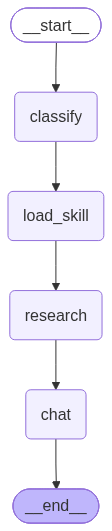

In [10]:
# Graph
graph = StateGraph(ChatState)
graph.add_node("chat", chat_node)
graph.add_node("classify", classify_node)
graph.add_node("load_skill", load_skill_node)
graph.add_node("research", research_node)
graph.add_edge(START, "classify")
graph.add_edge("classify", "load_skill")
graph.add_edge("load_skill", "research")
graph.add_edge("research", "chat")
graph.add_edge("chat", END)

workflow = graph.compile()
workflow

In [11]:
workflow.invoke({"messages": HumanMessage(content="When will i get love")})

Question When will i get love


{'messages': [HumanMessage(content='When will i get love', additional_kwargs={}, response_metadata={}, id='b3bb4d5c-e9e5-4708-986f-b89badb73ac4')],
 'category': 'relationships',
 'skill_instructions': '# Relationships Astrology Skill\n\n## Purpose\n\nAnswer questions about relationship patterns, attachment needs, communication, compatibility, partnership timing, and relational growth. Keep the reading respectful, consent-aware, and non-deterministic.\n\n## Required inputs\n\nFor an individual reading, collect or confirm date of birth, accurate birth time, and birthplace. For compatibility or synastry, collect those details separately for each consenting person, clearly label whose details belong to whom, and note any unknown or estimated times.\n\nFor a current relationship-timing question, also collect the relevant date range. Do not request private information about a third party without a legitimate, consent-based reason.\n\n## Tools and calculations\n\nUse a trusted chart calculato